In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from scipy.stats import randint, uniform

import warnings
warnings.filterwarnings("ignore")

In [4]:
df = pd.read_csv("Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
print("Dataset Shape:", df.shape)

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

df.drop("customerID", axis=1, inplace=True)

df["Churn"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

print(df.isnull().sum())

print("\nClass Distribution:")
print(df["Churn"].value_counts())

Dataset Shape: (7043, 21)
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Class Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [6]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 19)
Testing data: (1409, 19)


In [7]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        eval_metric="logloss",
        random_state=42
    )
}

trained_models = {}
results = {}
probabilities = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)

    trained_models[name] = pipeline
    probabilities[name] = y_prob

    results[name] = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": auc
    }

    print("\nModel:", name)
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))
    print("ROC-AUC:", round(auc, 4))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))


Model: Logistic Regression
Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
F1 Score: 0.604
ROC-AUC: 0.8419
Confusion Matrix:
[[926 109]
 [165 209]]

Model: Random Forest
Accuracy: 0.7637
Precision: 0.5485
Recall: 0.6203
F1 Score: 0.5822
ROC-AUC: 0.8225
Confusion Matrix:
[[844 191]
 [142 232]]

Model: XGBoost
Accuracy: 0.807
Precision: 0.6735
Recall: 0.5294
F1 Score: 0.5928
ROC-AUC: 0.8444
Confusion Matrix:
[[939  96]
 [176 198]]


In [8]:
comparison = pd.DataFrame(results).T

comparison

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.805536,0.657233,0.558824,0.604046,0.841861
Random Forest,0.763662,0.548463,0.620321,0.582183,0.822457
XGBoost,0.806955,0.673469,0.529412,0.592814,0.844371


In [9]:
print("Churn Class Distribution:")
print(y.value_counts())

print("\nChurn Percentage:")
print(y.value_counts(normalize=True) * 100)

Churn Class Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64

Churn Percentage:
Churn
0    73.463013
1    26.536987
Name: proportion, dtype: float64


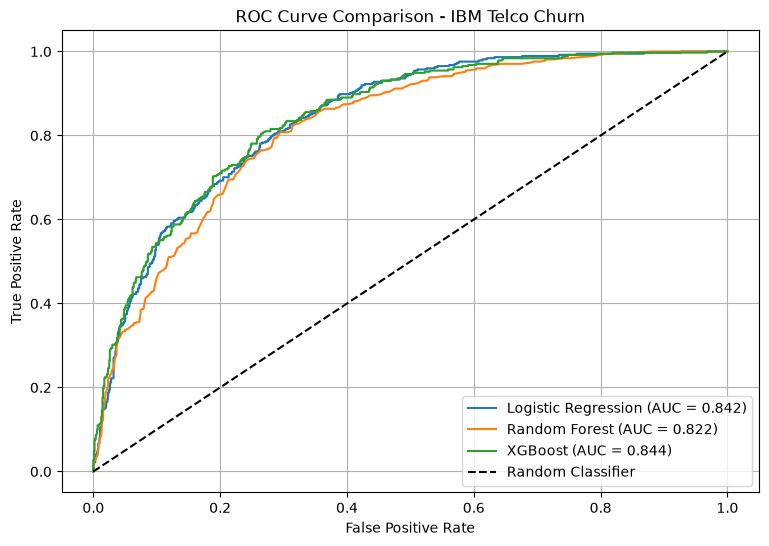

In [10]:
plt.figure(figsize=(9, 6))

for name, y_prob in probabilities.items():

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    auc = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison - IBM Telco Churn")

plt.legend()
plt.grid()
plt.show()

In [11]:
best_model_name = max(
    results,
    key=lambda x: results[x]["ROC-AUC"]
)

best_model = trained_models[best_model_name]

best_prob = best_model.predict_proba(X_test)[:, 1]

threshold_data = []

for threshold in np.arange(0.01, 1.00, 0.01):

    predictions = (best_prob >= threshold).astype(int)

    recall = recall_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions, zero_division=0
    )

    if recall >= 0.75:

        threshold_data.append({
            "Threshold": threshold,
            "Precision": precision,
            "Recall": recall
        })

threshold_df = pd.DataFrame(threshold_data)

if not threshold_df.empty:

    best_threshold_row = threshold_df.loc[
        threshold_df["Precision"].idxmax()
    ]

    print("Best Model:", best_model_name)
    print("Selected Threshold:",
          round(best_threshold_row["Threshold"], 2))

    print("Precision:",
          round(best_threshold_row["Precision"], 4))

    print("Recall:",
          round(best_threshold_row["Recall"], 4))

else:
    print("No threshold achieved 75% recall.")

Best Model: XGBoost
Selected Threshold: 0.29
Precision: 0.5302
Recall: 0.7754


In [12]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

rf_params = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [5, 10, 20, None],
    "classifier__min_samples_split": [2, 5, 10]
}

rf_grid = GridSearchCV(
    rf_pipeline,
    rf_params,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("Best CV ROC-AUC:")
print(rf_grid.best_score_)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best Random Forest Parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 300}
Best CV ROC-AUC:
0.845777774397915


In [13]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        eval_metric="logloss",
        random_state=42
    ))
])

xgb_params = {
    "classifier__n_estimators": randint(100, 400),
    "classifier__max_depth": randint(3, 10),
    "classifier__learning_rate": uniform(0.01, 0.2),
    "classifier__subsample": uniform(0.7, 0.3),
    "classifier__colsample_bytree": uniform(0.7, 0.3)
}

xgb_random = RandomizedSearchCV(
    xgb_pipeline,
    xgb_params,
    n_iter=15,
    cv=5,
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_random.fit(X_train, y_train)

print("Best XGBoost Parameters:")
print(xgb_random.best_params_)

print("Best CV ROC-AUC:")
print(xgb_random.best_score_)

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best XGBoost Parameters:
{'classifier__colsample_bytree': np.float64(0.7468055921327309), 'classifier__learning_rate': np.float64(0.041198904067240534), 'classifier__max_depth': 5, 'classifier__n_estimators': 187, 'classifier__subsample': np.float64(0.8001125833417065)}
Best CV ROC-AUC:
0.8447314870999334


In [14]:
tuned_models = {
    "Logistic Regression": trained_models["Logistic Regression"],
    "Random Forest": rf_grid.best_estimator_,
    "XGBoost": xgb_random.best_estimator_
}

cv_scores = {
    "Logistic Regression": results["Logistic Regression"]["ROC-AUC"],
    "Random Forest": rf_grid.best_score_,
    "XGBoost": xgb_random.best_score_
}

best_model_name = max(cv_scores, key=cv_scores.get)

best_classifier = tuned_models[best_model_name]

print("Best Model:", best_model_name)
print("Selection ROC-AUC:", round(cv_scores[best_model_name], 4))

Best Model: Random Forest
Selection ROC-AUC: 0.8458


FINAL BEST MODEL: Random Forest
Accuracy: 0.752306600425834
Precision: 0.5229357798165137
Recall: 0.7620320855614974
F1 Score: 0.6202393906420022
ROC-AUC: 0.8394753158180267

Final Confusion Matrix:


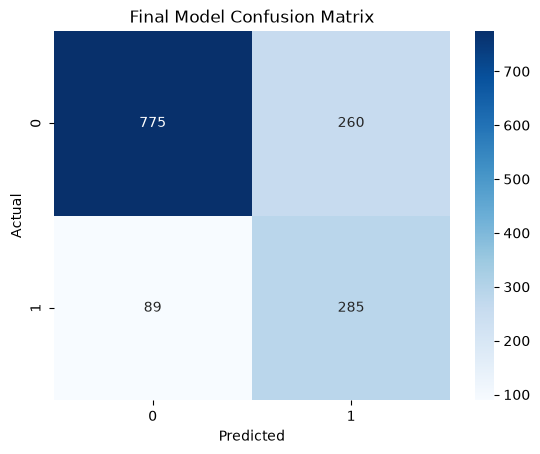

In [15]:
final_predictions = best_classifier.predict(X_test)

final_probabilities = best_classifier.predict_proba(
    X_test
)[:, 1]

print("FINAL BEST MODEL:", best_model_name)

print("Accuracy:",
      accuracy_score(y_test, final_predictions))

print("Precision:",
      precision_score(y_test, final_predictions))

print("Recall:",
      recall_score(y_test, final_predictions))

print("F1 Score:",
      f1_score(y_test, final_predictions))

print("ROC-AUC:",
      roc_auc_score(y_test, final_probabilities))

print("\nFinal Confusion Matrix:")

sns.heatmap(
    confusion_matrix(y_test, final_predictions),
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Final Model Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [16]:
# Prepare regression dataset

reg_df = df.dropna(subset=["TotalCharges"]).copy()

X_reg = reg_df.drop(
    ["TotalCharges", "Churn"],
    axis=1
)

y_reg = reg_df["TotalCharges"]

num_reg = X_reg.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

cat_reg = X_reg.select_dtypes(
    include=["object"]
).columns.tolist()

reg_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_reg),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_reg)
])

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

reg_model = Pipeline([
    ("preprocessor", reg_preprocessor),
    ("regressor", LinearRegression())
])

reg_model.fit(Xr_train, yr_train)

reg_predictions = reg_model.predict(Xr_test)

# Mean baseline
mean_predictions = np.full(
    len(yr_test),
    yr_train.mean()
)

# Regression metrics
mae = mean_absolute_error(
    yr_test, reg_predictions
)

rmse = np.sqrt(
    mean_squared_error(yr_test, reg_predictions)
)

r2 = r2_score(
    yr_test, reg_predictions
)

# Baseline metrics
baseline_mae = mean_absolute_error(
    yr_test, mean_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(yr_test, mean_predictions)
)

baseline_r2 = r2_score(
    yr_test, mean_predictions
)

print("REGRESSION MODEL: LINEAR REGRESSION")

print("\nLinear Regression:")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

print("\nMean Baseline:")
print("MAE:", round(baseline_mae, 4))
print("RMSE:", round(baseline_rmse, 4))
print("R2 Score:", round(baseline_r2, 4))

REGRESSION MODEL: LINEAR REGRESSION

Linear Regression:
MAE: 541.0229
RMSE: 673.9498
R2 Score: 0.9121

Mean Baseline:
MAE: 1907.3184
RMSE: 2273.5768
R2 Score: -0.0003


In [19]:

print("FINAL EVALUATION SUMMARY")

print("\nBest Classification Model:", best_model_name)

print("ROC-AUC:",
      round(roc_auc_score(y_test, final_probabilities), 4))

print("F1 Score:",
      round(f1_score(y_test, final_predictions), 4))

print("\nRegression Results")

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R2:", round(r2, 4))

print("\nMean Baseline Results")

print("MAE:", round(baseline_mae, 4))
print("RMSE:", round(baseline_rmse, 4))
print("R2:", round(baseline_r2, 4))



FINAL EVALUATION SUMMARY

Best Classification Model: Random Forest
ROC-AUC: 0.8395
F1 Score: 0.6202

Regression Results
MAE: 541.0229
RMSE: 673.9498
R2: 0.9121

Mean Baseline Results
MAE: 1907.3184
RMSE: 2273.5768
R2: -0.0003
